# 02 — What does the model rely on?

The test set is the final exam: we must not use it to make decisions (spec 8.1). So we split the **training** data:
- **fit** (80%): the model learns from this
- **validation** (20%): we inspect and tune with this

`stratify=y` keeps the attack/normal ratio identical in both parts.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from cybershield.ml.preprocessing import TRAIN_CSV, TEST_CSV, load_csv, split_xy
from cybershield.ml.train import build_model, evaluate, SEED

X, y = split_xy(load_csv(TRAIN_CSV))
X_fit, X_val, y_fit, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
model = build_model().fit(X_fit, y_fit)

val = evaluate(y_val, model.predict(X_val))
{k: round(v, 3) for k, v in val.items() if k != "confusion_matrix"}

{'precision': 0.965,
 'recall': 0.977,
 'f1': 0.971,
 'false_positive_rate': 0.076}

## Validation vs test
On test the same kind of model had a **26.8%** false-positive rate. Compare with validation above: validation comes from the *same* recordings as training, test does not. A big gap means the model learned patterns specific to the training recordings.

## Importance method 1: built-in (impurity)
Each time a tree splits on a feature, the split makes the groups "purer" (more all-attack or all-normal). Summing that improvement per feature over all 100 trees gives `feature_importances_`.

The one-hot encoder made 104 `proto_*` columns, so we add them back up into one `proto` score per original column.

Caveat: computed on **training** data, and biased toward features with many distinct values.

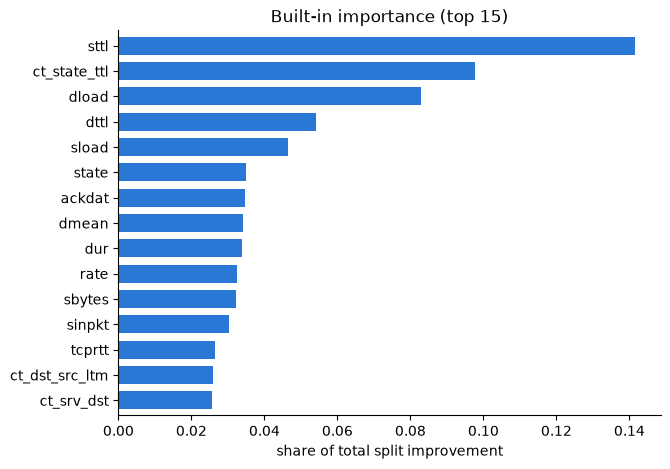

In [2]:
COLOR = "#2a78d6"
names = model[:-1].get_feature_names_out()
imp = pd.Series(model[-1].feature_importances_, index=names)
original = imp.index.str.replace(r"^(proto|service|state)_.*", r"\1", regex=True)
impurity = imp.groupby(original).sum().sort_values()

ax = impurity.tail(15).plot.barh(color=COLOR, figsize=(7, 5), width=0.7)
ax.set(title="Built-in importance (top 15)", xlabel="share of total split improvement")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Importance method 2: permutation
Take the validation set, **shuffle one column** (break its link to the answer), and measure how much the score drops. Big drop = the model depends on that feature.

Works on held-out data and on the original columns directly, so it is the more trustworthy of the two. We use balanced accuracy, where 0.5 = guessing.

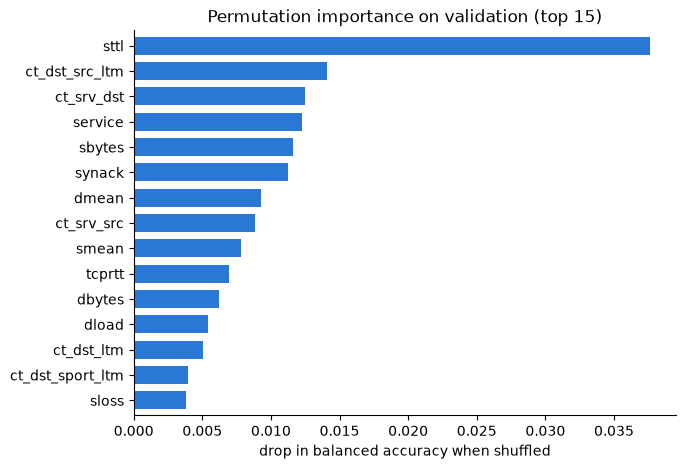

features whose shuffling changes nothing: 9 of 42


In [3]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(model, X_val, y_val, scoring="balanced_accuracy",
                              n_repeats=3, random_state=SEED, n_jobs=-1)
perm = pd.Series(perm.importances_mean, index=X_val.columns).sort_values()

ax = perm.tail(15).plot.barh(color=COLOR, figsize=(7, 5), width=0.7)
ax.set(title="Permutation importance on validation (top 15)", xlabel="drop in balanced accuracy when shuffled")
ax.spines[["top", "right"]].set_visible(False)
plt.show()
print("features whose shuffling changes nothing:", (perm.abs() < 0.0005).sum(), "of", len(perm))